# 04 - Transformer model (module 3)


Fine-tuning a BERT-type model for multi-label emotion classification on GoEmotions (28 labels), then comparison with the linear baseline.

**Step 1 (this part):** environment, data loading, multi-hot labels, tokenizer choice and token length analysis.

Runs on **Google Colab with a GPU** (Runtime > Change runtime type > T4 GPU).

## 1. GPU check

In [1]:
import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


## 2. Libraries and seed

In [2]:
!pip install -q transformers datasets

In [3]:
import os
import subprocess
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, set_seed

SEED = 42
set_seed(SEED)   # fixes the seeds of random, numpy and torch

print("transformers:", transformers.__version__)
print("pandas:", pd.__version__)

transformers: 5.22.1
pandas: 2.2.3


## 3. Data

We use the clean splits produced by `01_eda_simple.ipynb` (duplicates removed, labels at three levels).
The `data/` folder is not on GitHub, so the files are kept on Google Drive:
`MyDrive/ML_Project/data/processed/{train,validation,test}.parquet`.

If they are not there yet, the cell below clones the repository, runs `01_eda_simple.ipynb` and copies the files to Drive.
This way the transformer uses **exactly the same splits** as the baseline.

In [4]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/ML_Project"
DATA_DIR = os.path.join(PROJECT_DIR, "data", "processed")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results", "transformer")
os.makedirs(RESULTS_DIR, exist_ok = True)

if not os.path.exists(os.path.join(DATA_DIR, "train.parquet")):
    print("Processed data not found on Drive: regenerating it from the repository...")
    repo = "/content/ML_Project"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "https://github.com/lucaperkins/ML_Project", repo], check = True)
    subprocess.run(["jupyter", "nbconvert", "--to", "notebook", "--execute",
                    "01_eda_simple.ipynb", "--output", "/tmp/01_executed.ipynb"],
                   cwd = os.path.join(repo, "notebooks"), check = True)
    shutil.copytree(os.path.join(repo, "data", "processed"), DATA_DIR, dirs_exist_ok = True)

print(sorted(os.listdir(DATA_DIR)))

Mounted at /content/drive
Processed data not found on Drive: regenerating it from the repository...
['test.parquet', 'train.parquet', 'validation.parquet']


In [5]:
df_train = pd.read_parquet(os.path.join(DATA_DIR, "train.parquet"))
df_val = pd.read_parquet(os.path.join(DATA_DIR, "validation.parquet"))
df_test = pd.read_parquet(os.path.join(DATA_DIR, "test.parquet"))

print("Train:", df_train.shape, "Validation:", df_val.shape, "Test:", df_test.shape)
df_train.head()

Train: (43190, 5) Validation: (5377, 5) Test: (5379, 5)


,id,text,labels_28,labels_ekman,labels_sentiment
0,eebbqej,My favourite food is anything I didn't have to...,[neutral],[neutral],[neutral]
1,ed00q6i,"Now if he does off himself, everyone will thin...",[neutral],[neutral],[neutral]
2,eezlygj,WHY THE FUCK IS BAYLESS ISOING,[anger],[anger],[negative]
3,ed7ypvh,To make her feel threatened,[fear],[fear],[negative]
4,ed0bdzj,Dirty Southern Wankers,[annoyance],[anger],[negative]


**Sanity check:** the sizes must match the summary of `01_eda_simple.ipynb` (43,190 / 5,377 / 5,379).
The test set is loaded only to check it, it is **not used** before the final evaluation.

In [6]:
assert len(df_train) == 43190 and len(df_val) == 5377 and len(df_test) == 5379, "Splits differ from 01_eda_simple.ipynb"

## 4. Multi-hot labels

Each comment becomes a vector of 28 values (1 if the label is present, 0 otherwise).
The label order is the **official GoEmotions order** and must be the same in the baseline notebook, otherwise the comparison per label is wrong.

The values are **float32**: the multi-label loss (binary cross-entropy) expects floats, not integers.

In [7]:
LABELS = ["admiration", "amusement", "anger", "annoyance", "approval", "caring", "confusion",
          "curiosity", "desire", "disappointment", "disapproval", "disgust", "embarrassment",
          "excitement", "fear", "gratitude", "grief", "joy", "love", "nervousness", "optimism",
          "pride", "realization", "relief", "remorse", "sadness", "surprise", "neutral"]
assert len(LABELS) == 28

def to_multi_hot(label_lists, labels = LABELS):
    index = {name: i for i, name in enumerate(labels)}
    y = np.zeros((len(label_lists), len(labels)), dtype = np.float32)
    for row, names in enumerate(label_lists):
        for name in names:
            y[row, index[name]] = 1.0
    return y

y_train = to_multi_hot(df_train["labels_28"])
y_val = to_multi_hot(df_val["labels_28"])

print("y_train:", y_train.shape, y_train.dtype)
print("Every comment has at least one label:", bool((y_train.sum(axis = 1) >= 1).all()))
print("Comments with several labels:", round(100 * (y_train.sum(axis = 1) > 1).mean(), 1), "%")

y_train: (43190, 28) float32
Every comment has at least one label: True
Comments with several labels: 16.5 %


In [8]:
# check against the EDA: number of train comments per label
pd.Series(y_train.sum(axis = 0).astype(int), index = LABELS).sort_values(ascending = False)

,0
neutral,14183
admiration,4118
approval,2938
gratitude,2613
annoyance,2468
amusement,2327
curiosity,2187
love,2062
disapproval,2020
optimism,1578


## 5. Choice of the model and tokenizer

We use **`distilbert-base-cased`** (Sanh et al., 2019):
- **DistilBERT** is a smaller, faster version of BERT (about 40% smaller, 60% faster, keeping about 97% of BERT's language understanding according to its authors). It fits in the free Colab GPU and in our time budget.
- **Cased** keeps capital letters. The EDA showed that capitals and punctuation carry emotion (e.g. *"WHY THE FUCK IS BAYLESS ISOING"*), and an *uncased* model would lowercase everything and lose this signal.

In [9]:
MODEL_NAME = "distilbert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

for text in ["WHY THE FUCK IS BAYLESS ISOING",
             "Thanks so much!! I really appreciate it",
             "I miss [NAME]",
             "This is amazing 😂😂"]:
    print(text)
    print("   ->", tokenizer.tokenize(text))

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

WHY THE FUCK IS BAYLESS ISOING
   -> ['W', '##H', '##Y', 'THE', 'F', '##UC', '##K', 'IS', 'BA', '##Y', '##LE', '##SS', 'ISO', '##ING']
Thanks so much!! I really appreciate it
   -> ['Thanks', 'so', 'much', '!', '!', 'I', 'really', 'appreciate', 'it']
I miss [NAME]
   -> ['I', 'miss', '[', 'N', '##AM', '##E', ']']
This is amazing 😂😂
   -> ['This', 'is', 'amazing', '[UNK]']


**What to look at:**
- Capitals give different tokens from lowercase words, so the signal is kept.
- `[NAME]` is split into several pieces. It is not a special token for the model.
- Emojis may become `[UNK]` (unknown token), so their emotional signal is lost. We measure how often this happens below.

## 6. Length in tokens

The EDA counted **words**. The model works on **tokens** (sub-words), so a text has more tokens than words.
We choose `MAX_LEN` (the maximum length given to the model) so that almost no text is truncated, while keeping it small: a shorter `MAX_LEN` means faster training.

Measured on **train only**.

In [10]:
encoded = tokenizer(list(df_train["text"]), add_special_tokens = True)["input_ids"]
n_tokens = pd.Series([len(ids) for ids in encoded])

print(n_tokens.describe().round(1))
for q in [0.95, 0.99, 1.0]:
    print(f"{int(q * 100)}% of texts have at most {int(n_tokens.quantile(q))} tokens")

count    43190.0
mean        20.2
std          9.2
min          3.0
25%         13.0
50%         20.0
75%         27.0
max        316.0
dtype: float64
95% of texts have at most 35 tokens
99% of texts have at most 41 tokens
100% of texts have at most 316 tokens


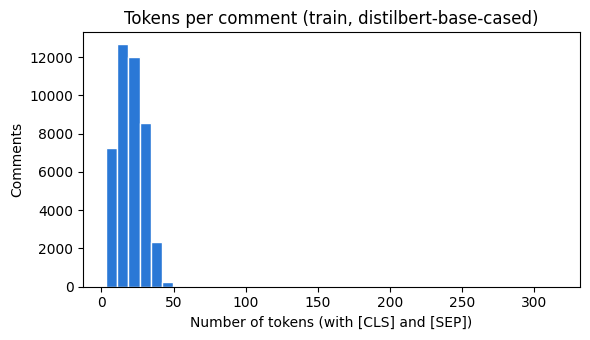

In [11]:
fig, ax = plt.subplots(figsize = (6, 3.5))
ax.hist(n_tokens, bins = 40, color = "#2a78d6", edgecolor = "white")
ax.set_title("Tokens per comment (train, " + MODEL_NAME + ")")
ax.set_xlabel("Number of tokens (with [CLS] and [SEP])")
ax.set_ylabel("Comments")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "token_length.png"))
plt.show()

In [12]:
for max_len in [32, 48, 64, 96, 128]:
    truncated = (n_tokens > max_len).mean()
    print(f"MAX_LEN = {max_len:>3}: {100 * truncated:.2f}% of train texts truncated")

MAX_LEN =  32: 10.17% of train texts truncated
MAX_LEN =  48: 0.22% of train texts truncated
MAX_LEN =  64: 0.03% of train texts truncated
MAX_LEN =  96: 0.01% of train texts truncated
MAX_LEN = 128: 0.00% of train texts truncated


In [13]:
# share of texts containing an unknown token
unk_id = tokenizer.unk_token_id
has_unk = pd.Series([unk_id in ids for ids in encoded])
print("Train texts with at least one [UNK] token:", round(100 * has_unk.mean(), 2), "%")
print("Examples:")
for t in df_train["text"][has_unk.values].head(5):
    print("  ", t)

Train texts with at least one [UNK] token: 2.01 %
Examples:
   Yes I heard abt the f bombs! That has to be why. Thanks for your reply:) until then hubby and I will anxiously wait 😝
   sorry [NAME]! 😘😘😘
   omg [NAME] and his dad walking out together is so cute 😍
   Lmao Stole my joke! 😂
   I always just say “thank you” because it’s a nice thought 🤷‍♀️


In [14]:
# inspect the longest texts in tokens
longest = n_tokens.sort_values(ascending = False).head(5)
for i, n in longest.items():
    print(n, "tokens:", df_train["text"].iloc[i][:150])

316 tokens: here you go: |Games|Home|Away|Team|vs W-L 18-19| |:-|:-|:-|:-|-:| |1|1|0|Golden State|0-1| |2|1|1|Houston|0-0| |2|1|1|Oklahoma City|0-0| |2|0|2|Toront
120 tokens: ackchyually, it's *r/woooosh ^^^^^I'm ^^^^^a ^^^^^bot. ^^^^^Complaints ^^^^^should ^^^^^be ^^^^^sent ^^^^^to ^^^^^u/stumblinbear ^^^^^where ^^^^^they 
99 tokens: >It also means no applause lines. No problem, just get the white house staff to clap for.... OHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHH
86 tokens: Oh fuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuck RIGHT OFF!!!!!
76 tokens: NO absolueltey wrong. WE MUST PRIORITIZE GETTING CORPORATE MONEY OUT OF POLITICS OR WE WILL NEVER BE ABLE TO SOLVE ANOTHER PROBLEM IN THIS COUNTRY.


## 7. Findings of step 1

- **Environment:** Tesla T4 GPU, PyTorch 2.14.1, transformers 5.22.1. The processed splits regenerated on Colab match `01_eda_simple.ipynb` exactly (43,190 / 5,377 / 5,379), so the transformer uses the same data as the baseline.
- **Labels:** 16.5% of train comments have several labels, which confirms the multi-label setting (sigmoid + binary cross-entropy, not softmax).
- **Token length:** median 20 tokens, 95% of texts under 35 and 99% under 41. The longest texts are not real long comments but Reddit artefacts: a Markdown table (316 tokens), a bot signature with superscript markers (120), words with repeated letters ("OHHHHHH", "fuuuuuuck", 86 to 99) and full-capital sentences (76). Truncating them at 64 tokens loses little emotional content.
- **Repeated letters:** they express intensity, but the tokenizer splits them into many meaningless pieces. Reducing repetitions to 3 letters is an option, to be decided with the data module and applied to the baseline as well.
- **Chosen `MAX_LEN` = 64:** it truncates only 0.03% of train texts. With dynamic padding, batches are padded to their longest text, so a larger `MAX_LEN` costs almost nothing.
- **Capital letters (correction of our first assumption):** the cased model keeps capitals, but words written fully in capitals are split into meaningless pieces ("WHY" -> W, ##H, ##Y). Cased is a trade-off, not a pure gain; cased vs uncased will be compared in step 3.
- **`[UNK]` tokens:** 2.01% of train texts, mostly emojis, which often carry strong emotion. Converting emojis to text is an option, to be applied to the baseline as well for a fair comparison.
- **`[NAME]` placeholder:** split into 5 sub-tokens. It will be added as a special token in step 2.